# MediaPipe walking experiment

This notebook is for exploration and visualization. The reusable implementation stays in `walk_analysis.cadence` and `walk_analysis.tracking`, so results can later be run reproducibly from the command line.

Use a fixed side-view video with one person and the full body visible. Cadence can be estimated from pose landmarks. Speed needs scene calibration because MediaPipe coordinates are normalized pixels, not meters.

In [44]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))
import cv2
import mediapipe as mp
import matplotlib.pyplot as plt
import numpy as np

from walk_analysis.cadence import estimate_metrics

VIDEO_PATH = PROJECT_ROOT / 'data' / 'walk.mp4'
MODEL_PATH = PROJECT_ROOT / 'models' / 'pose_landmarker_lite.task'
METERS_PER_NORMALIZED_HEIGHT = None  # Set after calibrating the scene.
if not VIDEO_PATH.exists():
    raise FileNotFoundError(f'Missing video: {VIDEO_PATH}. Add your video at data/walk.mp4.')
if not MODEL_PATH.exists():
    raise FileNotFoundError(f'Missing model: {MODEL_PATH}. Run `python -m walk_analysis download-model` from the workspace root.')

In [45]:
from walk_analysis.tracking import read_video_info
video_info = read_video_info(VIDEO_PATH)
fps = video_info.fps
frame_count = video_info.frame_count
width, height = video_info.width, video_info.height
duration_s = frame_count / fps
print({'fps': fps, 'frames': frame_count, 'size': (width, height), 'duration_s': duration_s})


{'fps': 23.976023976023978, 'frames': 254, 'size': (1920, 1080), 'duration_s': 10.593916666666665}


In [46]:
from walk_analysis.tracking import extract_pose_tracks
tracks = extract_pose_tracks(VIDEO_PATH, MODEL_PATH)
timestamps = tracks.timestamps
left_x, right_x = tracks.left_x, tracks.right_x
left_y, right_y = tracks.left_y, tracks.right_y
left_visibility, right_visibility = tracks.left_visibility, tracks.right_visibility
# Prefer the actual decoded count for evaluation coverage.
frame_count = tracks.processed_frames
print(f'Frames with pose: {timestamps.size}/{frame_count}')


W0000 00:00:1792759292.211669   35088 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792759292.227008   35089 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Frames with pose: 110/254


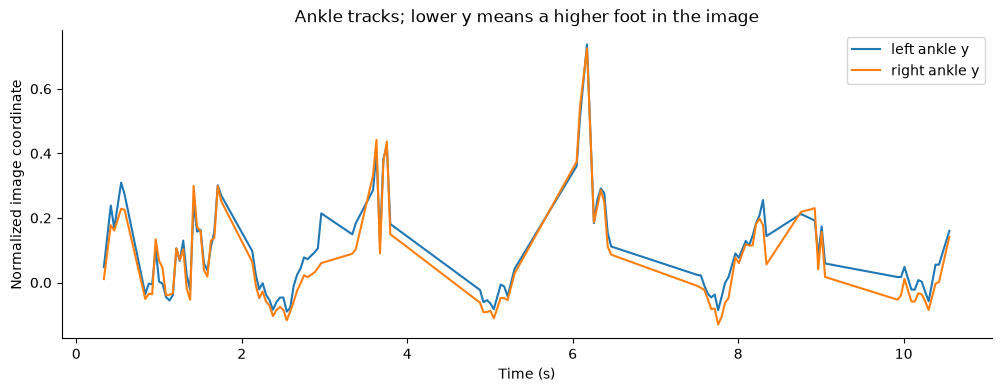

In [47]:
plt.figure(figsize=(12, 4))
plt.plot(timestamps, left_y, label='left ankle y')
plt.plot(timestamps, right_y, label='right ankle y')
plt.xlabel('Time (s)')
plt.ylabel('Normalized image coordinate')
plt.title('Ankle tracks; lower y means a higher foot in the image')
plt.legend()
plt.show()

In [48]:
metrics = estimate_metrics(
    timestamps, left_x, right_x, left_y, right_y,
    meters_per_normalized_height=METERS_PER_NORMALIZED_HEIGHT,
    left_visibility=left_visibility, right_visibility=right_visibility,
)
print(f'Detected steps: {metrics.detected_steps}')
print(f'Cadence: {metrics.cadence_steps_per_minute:.1f} steps/min')
print(f'Speed: {metrics.speed_m_per_s if metrics.speed_m_per_s is not None else "not calibrated"}')

Detected steps: 0
Cadence: 0.0 steps/min
Speed: not calibrated


## What to evaluate next

Manually count steps in the same video and compare that count with `Detected steps`. Try several walking speeds, camera distances, lighting conditions, and occlusions. Save landmark tracks and ground-truth counts before tuning thresholds. Only after cadence is stable should speed be calibrated and validated against a known walking distance and time.

## Debug the step candidates
The yellow flashes in the video are the exact peaks counted by the current algorithm, not verified foot contacts. Green lines show the pose; ankle labels show visibility. The preview is silent. Compare each event with a manually observed step.


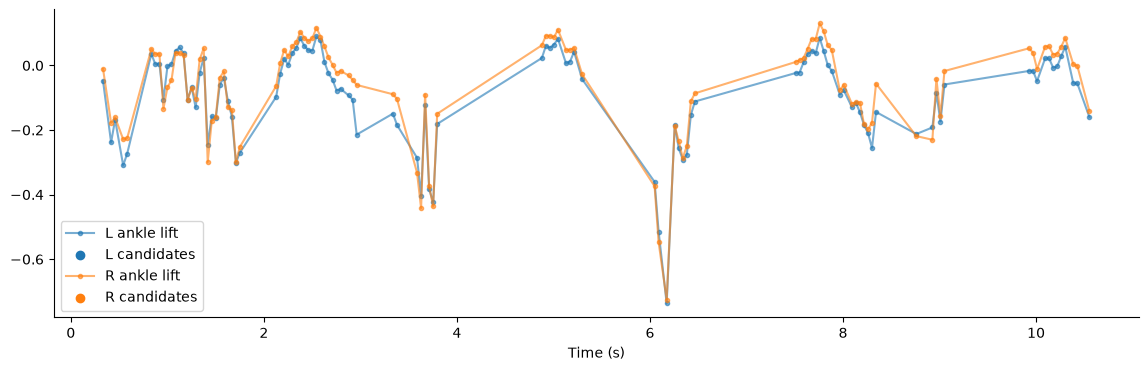

Candidate times (s): []


In [49]:
from walk_analysis.cadence import detect_step_candidates
candidates = detect_step_candidates(timestamps, left_y, right_y,
                                    left_visibility=left_visibility, right_visibility=right_visibility)
plt.figure(figsize=(14, 4))
for foot, values in [('L', left_y), ('R', right_y)]:
    plt.plot(timestamps, -values, '.-', alpha=0.6, label=f'{foot} ankle lift')
    events = [event for event in candidates if event.foot == foot]
    indices = np.asarray([event.index for event in events], dtype=int)
    plt.scatter(timestamps[indices], -values[indices], label=f'{foot} candidates')
for number, event in enumerate(candidates, 1):
    values = left_y if event.foot == 'L' else right_y
    plt.annotate(f'{number}{event.foot}', (timestamps[event.index], -values[event.index]))
plt.xlabel('Time (s)')
plt.legend()
plt.show()
print('Candidate times (s):', [(event.foot, round(float(timestamps[event.index]), 2)) for event in candidates])


## Evaluate the result
Run these cells after pose extraction and candidate detection. These figures help diagnose *why* a count changes; they do not establish accuracy without manual labels. Blue represents the left foot and orange the right throughout.


In [50]:
from IPython.display import Markdown, display
from walk_analysis.cadence import detect_step_candidates

foot_colors = {'L': 'tab:blue', 'R': 'tab:orange'}
eval_candidates = detect_step_candidates(
    timestamps, left_y, right_y,
    left_visibility=left_visibility, right_visibility=right_visibility,
)
event_times = np.asarray([timestamps[e.index] for e in eval_candidates], dtype=float)
event_feet = np.asarray([e.foot for e in eval_candidates])
clip_end_s = frame_count / fps
pose_frames = np.rint(timestamps * fps).astype(int)
pose_mask = np.zeros(frame_count, dtype=bool)
pose_mask[pose_frames] = True
visibility_tracks = {}
for foot, values in [('L', left_visibility), ('R', right_visibility)]:
    track = np.full(frame_count, np.nan)
    track[pose_frames] = values
    visibility_tracks[foot] = track

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})
display(Markdown(
    f'**Clip:** {clip_end_s:.2f} s · **Pose coverage:** {pose_mask.mean():.1%} '
    f'· **Candidates:** {len(event_times)} · '
    f'**L/R:** {np.sum(event_feet == "L")}/{np.sum(event_feet == "R")} '
    '\n\nCandidate counts are estimates, not manually verified steps.'
))


**Clip:** 10.59 s · **Pose coverage:** 43.3% · **Candidates:** 0 · **L/R:** 0/0 

Candidate counts are estimates, not manually verified steps.

### 1. Tracking quality: can we trust the inputs?
The top strip shows frames with a detected pose. The lower plot shows ankle visibility (0–1) and the 0.5 rejection threshold. Blank regions mean no pose, not zero visibility. Long gaps or low confidence explain missing candidates. High visibility alone does not prove that a landmark is correctly placed.


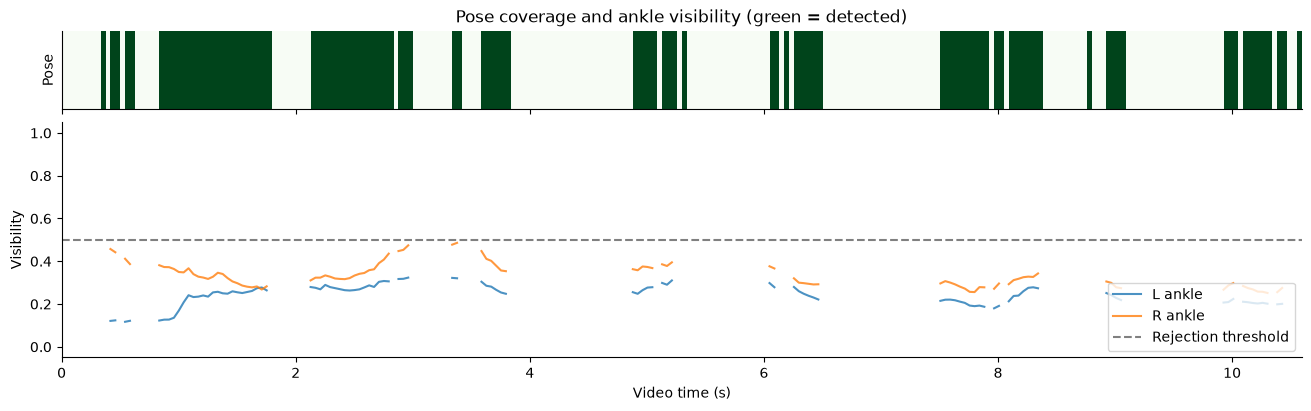

In [51]:
frame_times = np.arange(frame_count) / fps
fig, axes = plt.subplots(2, 1, figsize=(13, 4), sharex=True,
                         gridspec_kw={'height_ratios': [1, 3]}, constrained_layout=True)
axes[0].imshow(pose_mask[np.newaxis, :], aspect='auto', interpolation='nearest',
               extent=[0, clip_end_s, 0, 1], vmin=0, vmax=1, cmap='Greens')
axes[0].set_yticks([])
axes[0].set_ylabel('Pose')
axes[0].set_title('Pose coverage and ankle visibility (green = detected)')
for foot, track in visibility_tracks.items():
    axes[1].plot(frame_times, track, color=foot_colors[foot], label=f'{foot} ankle', alpha=.8)
axes[1].axhline(.5, color='gray', linestyle='--', label='Rejection threshold')
axes[1].set(xlabel='Video time (s)', ylabel='Visibility', ylim=(-.05, 1.05), xlim=(0, clip_end_s))
axes[1].legend(loc='lower right')
plt.show()


### 2. Event timeline and cumulative count: where does counting change?
Each tick is a candidate foot lift. In steady walking, many events should alternate, but the detector does not enforce alternation. Dense clusters can indicate double counts; long pauses can indicate stopped walking or missed tracking. The cumulative curve reveals where the total rises quickly. Repeated same-foot events are inspection hints, not automatically errors.


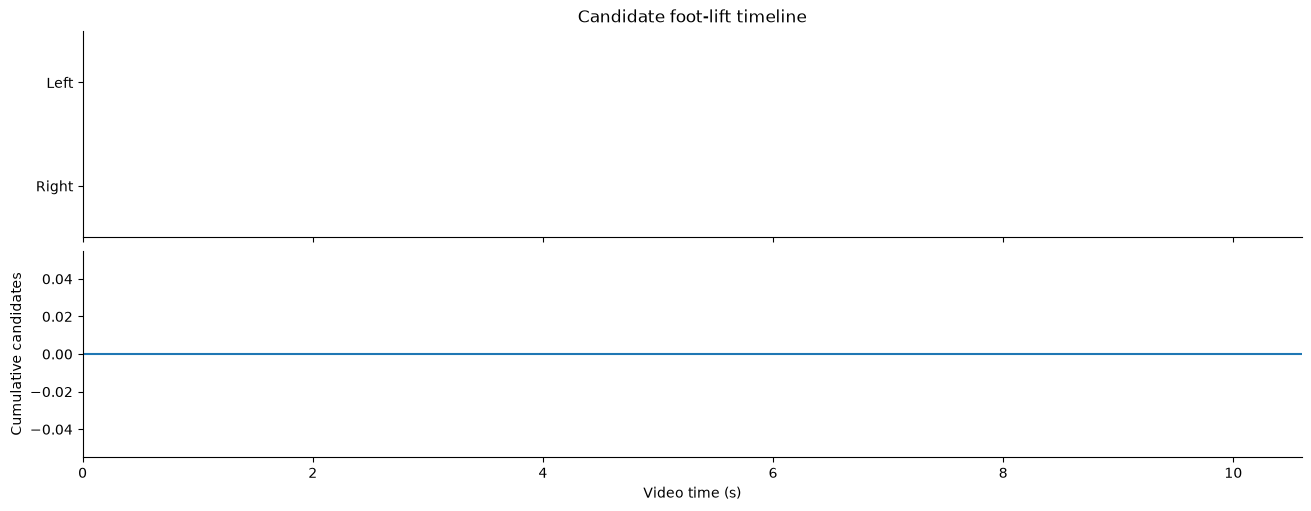

Consecutive same-foot events to inspect (s): []


In [52]:
fig, axes = plt.subplots(2, 1, figsize=(13, 5), sharex=True, constrained_layout=True)
for foot, level in [('L', 1), ('R', 0)]:
    ft = event_times[event_feet == foot]
    axes[0].scatter(ft, np.full(ft.size, level), marker='|', s=250,
                    color=foot_colors[foot], label=foot)
axes[0].set(yticks=[0, 1], yticklabels=['Right', 'Left'], ylim=(-.5, 1.5),
            title='Candidate foot-lift timeline')
axes[1].step(np.r_[0, event_times, clip_end_s],
             np.r_[0, np.arange(1, len(event_times) + 1), len(event_times)], where='post')
axes[1].set(xlabel='Video time (s)', ylabel='Cumulative candidates', xlim=(0, clip_end_s))
plt.show()
repeats = np.flatnonzero(event_feet[1:] == event_feet[:-1]) + 1
print('Consecutive same-foot events to inspect (s):', np.round(event_times[repeats], 2))


### 3. Time between candidates: is the rhythm plausible?
The scatter plot and histogram show intervals between consecutive candidates from either foot. Short intervals may be extra detections; long intervals may be missed steps, tracking gaps, or real pauses. The dashed line shows the configured minimum spacing, not a normal human reference. These are candidate intervals, not clinically measured stride times, and include tracking gaps.


In [53]:
intervals = np.diff(event_times)
if intervals.size:
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.5), constrained_layout=True)
    axes[0].scatter(event_times[1:], intervals, color='tab:purple', s=25)
    axes[0].axhline(.18, color='gray', linestyle='--', label='Minimum spacing: 0.18 s')
    axes[0].set(xlabel='Time of later candidate (s)', ylabel='Interval (s)', title='Candidate timing')
    axes[0].legend()
    axes[1].hist(intervals, bins=min(15, max(3, intervals.size)), color='tab:purple', alpha=.75)
    axes[1].set(xlabel='Interval (s)', ylabel='Number of intervals', title='Interval distribution')
    plt.show()
    print(f'Median interval: {np.median(intervals):.2f} s; range: {intervals.min():.2f}–{intervals.max():.2f} s')
else:
    print('At least two candidates are needed for interval plots.')


At least two candidates are needed for interval plots.


### 4. Local cadence and coverage: does the estimate change over time?
Bars count candidates in non-overlapping 5-second video windows and express them per minute. The last window uses its actual shorter duration. The lower plot shows pose coverage in the same windows. Low cadence with poor coverage can be a tracking issue; low cadence with good coverage could be a pause or a counting issue. Short windows are noisy. This uses video-window duration, whereas the overall metric uses the first-to-last detected-pose interval.


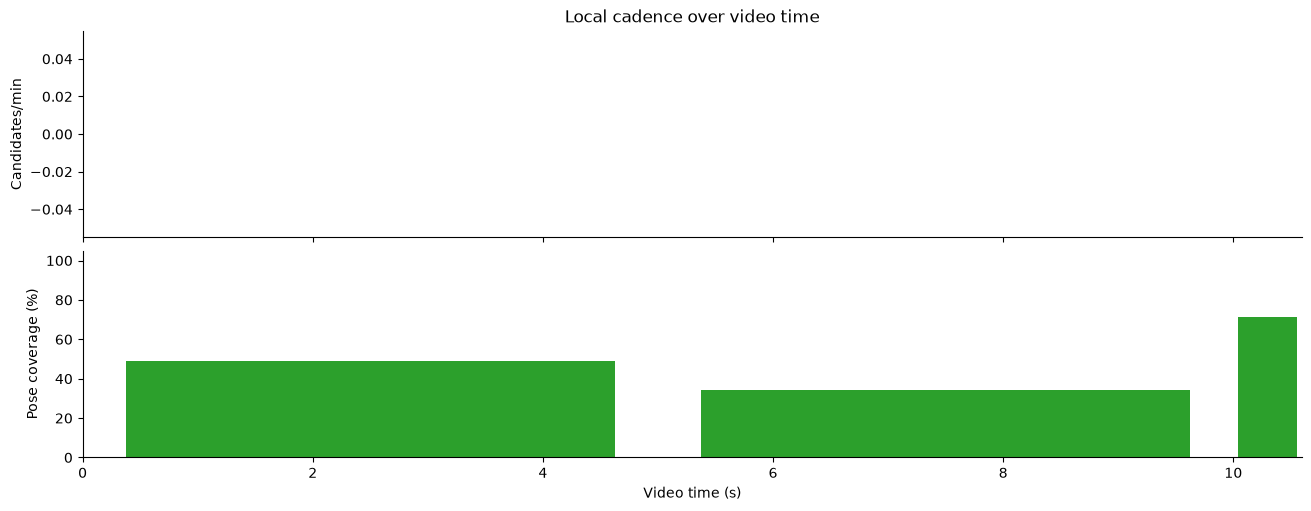

In [54]:
window_s = 5.0
edges = np.r_[np.arange(0, clip_end_s, window_s), clip_end_s]
widths = np.diff(edges)
centers = edges[:-1] + widths / 2
counts, _ = np.histogram(event_times, bins=edges)
coverage = np.asarray([pose_mask[(frame_times >= start) & (frame_times < end)].mean()
                       for start, end in zip(edges[:-1], edges[1:])])
fig, axes = plt.subplots(2, 1, figsize=(13, 5), sharex=True, constrained_layout=True)
axes[0].bar(centers, counts / widths * 60, width=widths * .85, color='tab:cyan')
axes[0].set(ylabel='Candidates/min', title='Local cadence over video time')
axes[1].bar(centers, coverage * 100, width=widths * .85, color='tab:green')
axes[1].set(xlabel='Video time (s)', ylabel='Pose coverage (%)', ylim=(0, 105), xlim=(0, clip_end_s))
plt.show()


### 5. Threshold sensitivity: is the count stable?
This grid varies ankle visibility and minimum peak prominence while keeping other defaults unchanged. Each cell is the candidate count. Large changes for small threshold changes indicate a fragile estimate that needs inspection. This is a diagnostic sweep; do not pick the setting that matches one known total and assume it generalizes. It does not modify the notebook's main metrics.


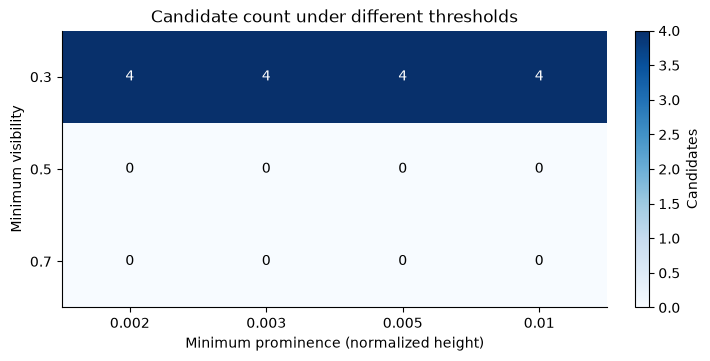

In [55]:
visibility_settings = [.3, .5, .7]
prominence_settings = [.002, .003, .005, .01]
sensitivity = np.zeros((len(visibility_settings), len(prominence_settings)), dtype=int)
for row, visibility in enumerate(visibility_settings):
    for col, prominence in enumerate(prominence_settings):
        sensitivity[row, col] = len(detect_step_candidates(
            timestamps, left_y, right_y,
            left_visibility=left_visibility, right_visibility=right_visibility,
            min_visibility=visibility, min_prominence=prominence,
        ))
fig, ax = plt.subplots(figsize=(7, 3.5), constrained_layout=True)
heatmap = ax.imshow(sensitivity, cmap='Blues', aspect='auto')
ax.set(xticks=np.arange(len(prominence_settings)), xticklabels=prominence_settings,
       yticks=np.arange(len(visibility_settings)), yticklabels=visibility_settings,
       xlabel='Minimum prominence (normalized height)', ylabel='Minimum visibility',
       title='Candidate count under different thresholds')
for row in range(sensitivity.shape[0]):
    for col in range(sensitivity.shape[1]):
        ax.text(col, row, str(sensitivity[row, col]), ha='center', va='center',
                color='white' if sensitivity[row, col] > (sensitivity.min()+sensitivity.max())/2 else 'black')
fig.colorbar(heatmap, ax=ax, label='Candidates')
plt.show()


### 6. Optional manual labels: measure accuracy
Enter **every manually observed foot-lift time** in the same evaluated interval, in seconds from the video start. Use foot lifts consistently because the detector estimates lifts, not foot contacts. If labeling contacts instead, a systematic timing offset is expected and timing errors need a different interpretation.

The comparison matches events one-to-one within the chosen tolerance: first maximizing matches, then minimizing absolute timing error. Precision measures how many detections match labels; recall measures how many labels were found; F1 balances both. The event plot highlights extras and misses. Total count error alone can hide both kinds of mistake. The tolerance defaults to 0.25 s and should be chosen before comparing algorithms. Empty labels skip evaluation rather than implying zero real steps.


In [56]:
# Fill these in after watching the video. Do not paste detector output as labels.
manual_step_times_s = []
evaluation_start_s = 0.0
evaluation_end_s = clip_end_s
matching_tolerance_s = 0.25


def match_event_times(detected, reference, tolerance):
    """Ordered one-to-one matching: maximize matches, then minimize timing error."""
    detected, reference = np.asarray(detected), np.asarray(reference)
    scores = [[(0, 0.0) for _ in range(len(reference)+1)] for _ in range(len(detected)+1)]
    actions = {}
    for i in range(1, len(detected)+1):
        for j in range(1, len(reference)+1):
            choices = [(scores[i-1][j], 'skip_detection'), (scores[i][j-1], 'skip_label')]
            error = abs(detected[i-1] - reference[j-1])
            if error <= tolerance:
                count, negative_error = scores[i-1][j-1]
                choices.append(((count+1, negative_error-error), 'match'))
            scores[i][j], actions[i,j] = max(choices, key=lambda item: item[0])
    i, j, pairs = len(detected), len(reference), []
    while i and j:
        action = actions[i,j]
        if action == 'match':
            pairs.append((i-1, j-1)); i -= 1; j -= 1
        elif action == 'skip_detection':
            i -= 1
        else:
            j -= 1
    return pairs[::-1]


if not manual_step_times_s:
    print('Manual evaluation skipped. Add foot-lift timestamps above to evaluate accuracy.')
else:
    labels = np.sort(np.asarray(manual_step_times_s, dtype=float))
    if not (0 <= evaluation_start_s < evaluation_end_s <= clip_end_s):
        raise ValueError('Choose an evaluation interval inside the video.')
    if (labels.ndim != 1 or not np.all(np.isfinite(labels)) or np.any(np.diff(labels) <= 0)
            or np.any(labels < evaluation_start_s) or np.any(labels > evaluation_end_s)):
        raise ValueError('Labels must be distinct finite timestamps inside the evaluation interval.')
    if not np.isfinite(matching_tolerance_s) or matching_tolerance_s <= 0:
        raise ValueError('Matching tolerance must be finite and positive.')
    detected = event_times[(event_times >= evaluation_start_s) & (event_times <= evaluation_end_s)]
    pairs = match_event_times(detected, labels, matching_tolerance_s)
    matched_d = {i for i, _ in pairs}
    matched_r = {j for _, j in pairs}
    tp, fp, fn = len(pairs), len(detected)-len(pairs), len(labels)-len(pairs)
    precision = tp / (tp+fp) if tp+fp else 0.0
    recall = tp / (tp+fn)
    f1 = 2*tp / (2*tp+fp+fn)
    display(Markdown(
        '| Measure | Result |\n|---|---:|\n'
        f'| Matched / extra / missed | {tp} / {fp} / {fn} |\n'
        f'| Precision | {precision:.1%} |\n| Recall | {recall:.1%} |\n| F1 | {f1:.1%} |\n'
        f'| Count error (detected − manual) | {len(detected)-len(labels):+d} |'
    ))
    fig, ax = plt.subplots(figsize=(13, 3), constrained_layout=True)
    for i, time in enumerate(detected):
        ax.scatter(time, 1, marker='|' if i in matched_d else 'x', s=100,
                   color='tab:green' if i in matched_d else 'tab:red')
    for j, time in enumerate(labels):
        ax.scatter(time, 0, marker='|' if j in matched_r else 'x', s=100,
                   color='tab:green' if j in matched_r else 'tab:red')
    for i, j in pairs:
        ax.plot([detected[i], labels[j]], [1, 0], color='gray', alpha=.4)
    ax.set(yticks=[0, 1], yticklabels=['Manual', 'Detected'], ylim=(-.5, 1.5),
           xlim=(evaluation_start_s, evaluation_end_s), xlabel='Video time (s)',
           title='Green: matched; red crosses: extra detection or missed label')
    plt.show()
    if pairs:
        errors = np.asarray([detected[i]-labels[j] for i,j in pairs])
        print(f'Mean absolute timing error: {np.mean(np.abs(errors)):.3f} s')
        print(f'Mean signed timing error (positive = late): {errors.mean():+.3f} s')


Manual evaluation skipped. Add foot-lift timestamps above to evaluate accuracy.


In [57]:
# Run the shared debug exporter and display the resulting video.
from pathlib import Path
import sys
from IPython.display import Video, display

project_root = Path.cwd().resolve()
if not (project_root / 'src' / 'walk_analysis').is_dir():
    project_root = project_root.parent
if not (project_root / 'src' / 'walk_analysis').is_dir():
    raise FileNotFoundError('Open this notebook from the project root or notebooks folder.')
sys.path.insert(0, str(project_root / 'src'))
from walk_analysis.debug import export_debug_video
export_debug_video(project_root / 'data/walk.mp4',
                   project_root / 'models/pose_landmarker_lite.task',
                   project_root / 'outputs')
display(Video(filename=str(project_root / 'outputs/walk_debug.mp4'), embed=True, width=960))


W0000 00:00:1792759304.437187   35134 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792759304.455170   35134 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Saved /workspaces/test_camera/outputs/walk_debug.mp4 (0 candidates, pose in 110/254 frames)
